# Graphviz layout demos
The way you arrange a graph's nodes can make its structure much easier to understand. This notebook explores seven Graphviz layout engines through examples that show where each one is useful.

The first cell installs the Python packages, and the next cell checks that the Graphviz programs are available. If any are missing, it shows the command to install them.

The examples use fixed random seeds. The exact node positions may still vary between Graphviz versions.

| Engine | What the example explores |
|---|---|
| Neato / FDP | How two layout engines arrange the same small network |
| SFDP | How to display a larger network with several groups of nodes |
| Circo | How circular layouts handle a ring and a wheel |
| Twopi | How a radial layout changes when you choose a different starting node |
| Dot | How to arrange a directed workflow from top to bottom or left to right |
| Patchwork | How to show grouped quantities as rectangles of different sizes |

In [9]:
%pip -q install networkx pydot matplotlib

In [10]:
import shutil
import subprocess
from time import perf_counter
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import networkx as nx
from networkx.drawing.nx_pydot import graphviz_layout
from IPython.display import Image, display

ENGINES = ['neato', 'fdp', 'sfdp', 'circo', 'twopi', 'dot', 'patchwork']
missing = [engine for engine in ENGINES if shutil.which(engine) is None]
if missing:
    raise RuntimeError(f"Missing Graphviz engines: {missing}. In Colab, run !apt-get -qq update && apt-get -qq install graphviz, then rerun.")
print(subprocess.run(['dot', '-V'], capture_output=True, text=True, check=True).stderr.strip())
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
PALETTE = ['#3B82F6', '#F59E0B', '#10B981', '#A855F7']


def layout(G, engine, root=None, **attributes):
    """Lay out a copy so demo-specific Graphviz attributes do not mutate G."""
    H = G.copy()
    H.graph['graph'] = dict(G.graph.get('graph', {}), **attributes)
    if engine in {'neato', 'fdp', 'sfdp'}:
        H.graph['graph'].setdefault('start', '42')
    return graphviz_layout(H, prog=engine, root=root)


def draw_graph(G, pos, title, ax=None, colors=None, labels=True, node_size=450):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size,
                           node_color=colors if colors is not None else PALETTE[0],
                           edgecolors='white', linewidths=0.8, alpha=0.95)
    # Arrow-specific options apply only to directed graphs.
    # Undirected graphs keep NetworkX's efficient LineCollection rendering.
    edge_options = dict(ax=ax, node_size=node_size,
                        edge_color='#64748B', alpha=0.55, width=1.2)
    if G.is_directed():
        edge_options.update(arrows=True, arrowstyle='-|>', arrowsize=16,
                            connectionstyle='arc3,rad=0.05')
    nx.draw_networkx_edges(G, pos, **edge_options)
    if labels:
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=9, font_color='#172554',
                               bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.75, 'pad': 0.3})
    ax.set_title(title, fontweight='bold', pad=12)
    ax.set_aspect('equal')
    ax.margins(0.12)
    ax.axis('off')
    return ax

dot - graphviz version 2.43.0 (0)


## 1–2. Neato and FDP: two ways to arrange the same network
Neato and FDP both arrange nodes using force-based methods. You can think of the edges as connections that help pull related nodes together, although the two engines calculate their layouts differently.

The two plots below show exactly the same network. We created it with three groups of nodes, with more connections within each group than between groups. Each group has its own color so you can follow it across the two plots. These colors come from the way we built the graph; the layout engines do not choose the groups.

Compare how tightly each group is drawn, how far apart the groups are, and where edges cross. One layout may make a particular feature easier to see, but neither is guaranteed to eliminate crossings.

**Try it:** The value `0.45` controls the chance of a connection within a group, and `0.04` controls the chance of a connection between groups. Lower the first value or raise the second, then rerun the cell. Are the three groups still easy to distinguish?

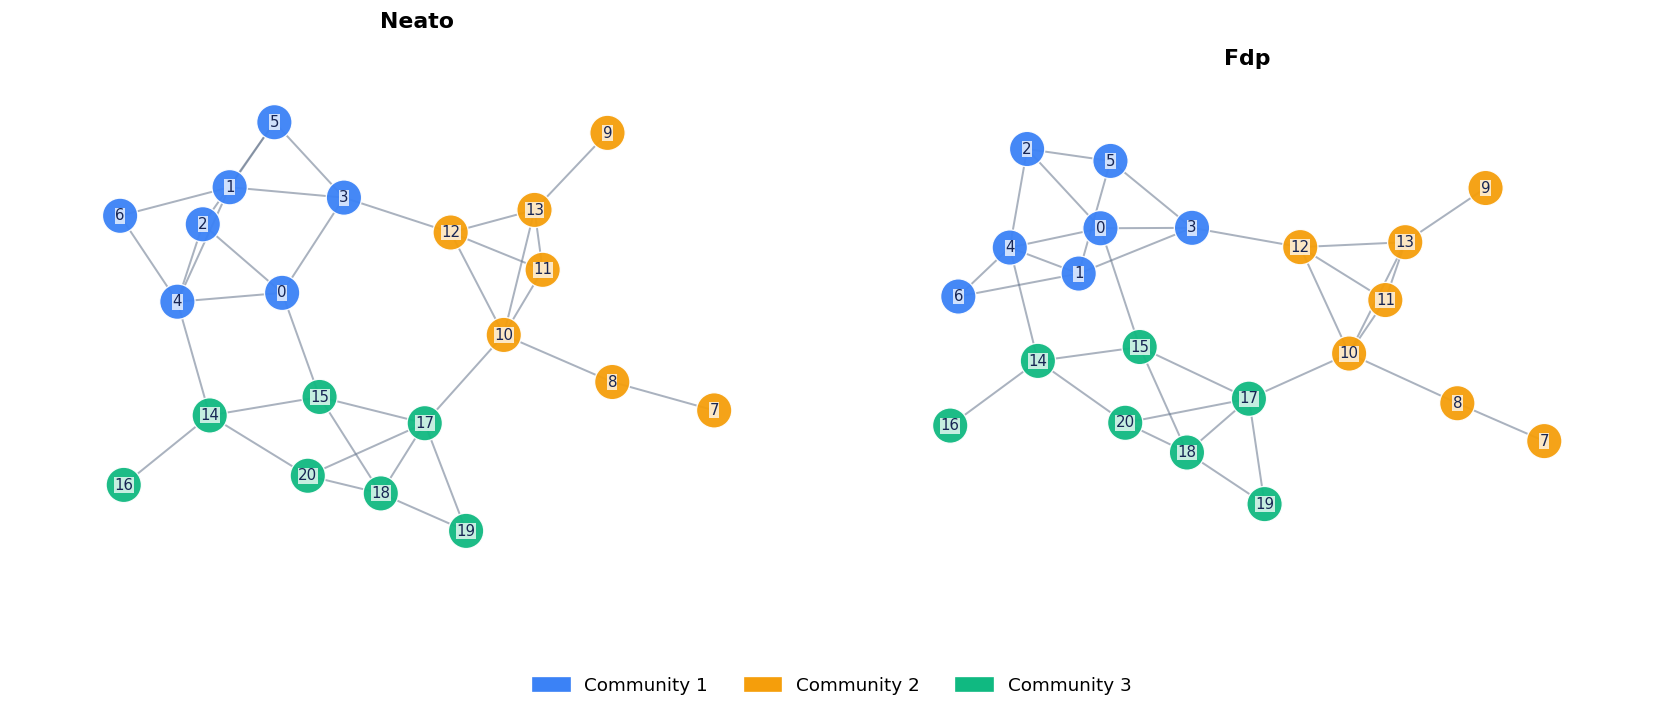

In [11]:
G_small = nx.stochastic_block_model([7, 7, 7],
    [[0.45, 0.04, 0.04], [0.04, 0.45, 0.04], [0.04, 0.04, 0.45]], seed=42)
small_colors = [PALETTE[G_small.nodes[n]['block']] for n in G_small]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for engine, ax in zip(['neato', 'fdp'], axes):
    draw_graph(G_small, layout(G_small, engine), engine.capitalize(), ax, small_colors)
fig.legend(handles=[Patch(color=PALETTE[i], label=f'Community {i + 1}') for i in range(3)],
           loc='lower center', ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## 3. SFDP: drawing a larger network
SFDP is designed for larger graphs. Here we give it a network with 240 nodes divided into four groups. As in the previous example, nodes are more likely to connect to others in their own group, and the colors show which group each node belongs to.

With this many nodes, individual labels would make the plot hard to read, so we leave them out. Look instead at the overall shape: do nodes of the same color tend to gather together, and which edges connect the groups?

The cell also reports how long the layout call takes. This includes preparing the graph for Graphviz and running the layout program, so use it as a rough guide when changing the graph size.

**Try it:** Change `sizes` to `[200, 200, 200, 200]` to draw an 800-node network. Then try increasing the between-group connection probability from `0.004` to `0.01`. How do these changes affect the layout and the time it takes to produce it?

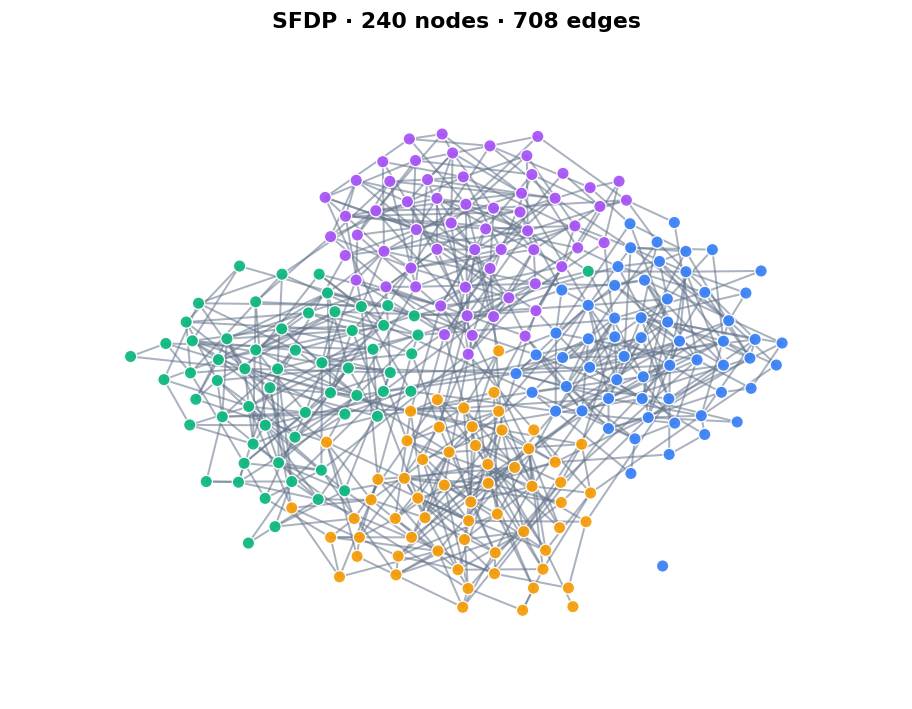

Layout call: 8.121 seconds


In [12]:
sizes = [60, 60, 60, 60]
probabilities = [[0.09 if i == j else 0.004 for j in range(4)] for i in range(4)]
G_large = nx.stochastic_block_model(sizes, probabilities, seed=42)
large_colors = [PALETTE[G_large.nodes[n]['block']] for n in G_large]
t0 = perf_counter()
pos_large = layout(G_large, 'sfdp', overlap='prism')
elapsed = perf_counter() - t0
draw_graph(G_large, pos_large,
           f'SFDP · {G_large.number_of_nodes()} nodes · {G_large.number_of_edges()} edges',
           colors=large_colors, labels=False, node_size=55)
plt.tight_layout()
plt.show()
print(f'Layout call: {elapsed:.3f} seconds')

## 4. Circo: drawing a ring and a wheel
Circo arranges nodes in circular patterns, which makes it useful for exploring graphs with loops. The first plot shows a simple ring: each node is connected to its two neighbors, forming one closed loop.

The second plot shows a wheel. It has a ring around the outside and one additional node connected to every node on that ring. This highly connected node is called the hub, and we color it orange so it is easy to find.

Compare the two drawings and follow the edges from the orange hub. Although the name “wheel” suggests a hub in the middle, Circo does not require it to be there. The example shows how a circular layout handles both the loop and the extra connections.

**Try it:** Add a third plot with two separate rings connected by a single edge. Does Circo make it easy to see the two rings and the connection between them?

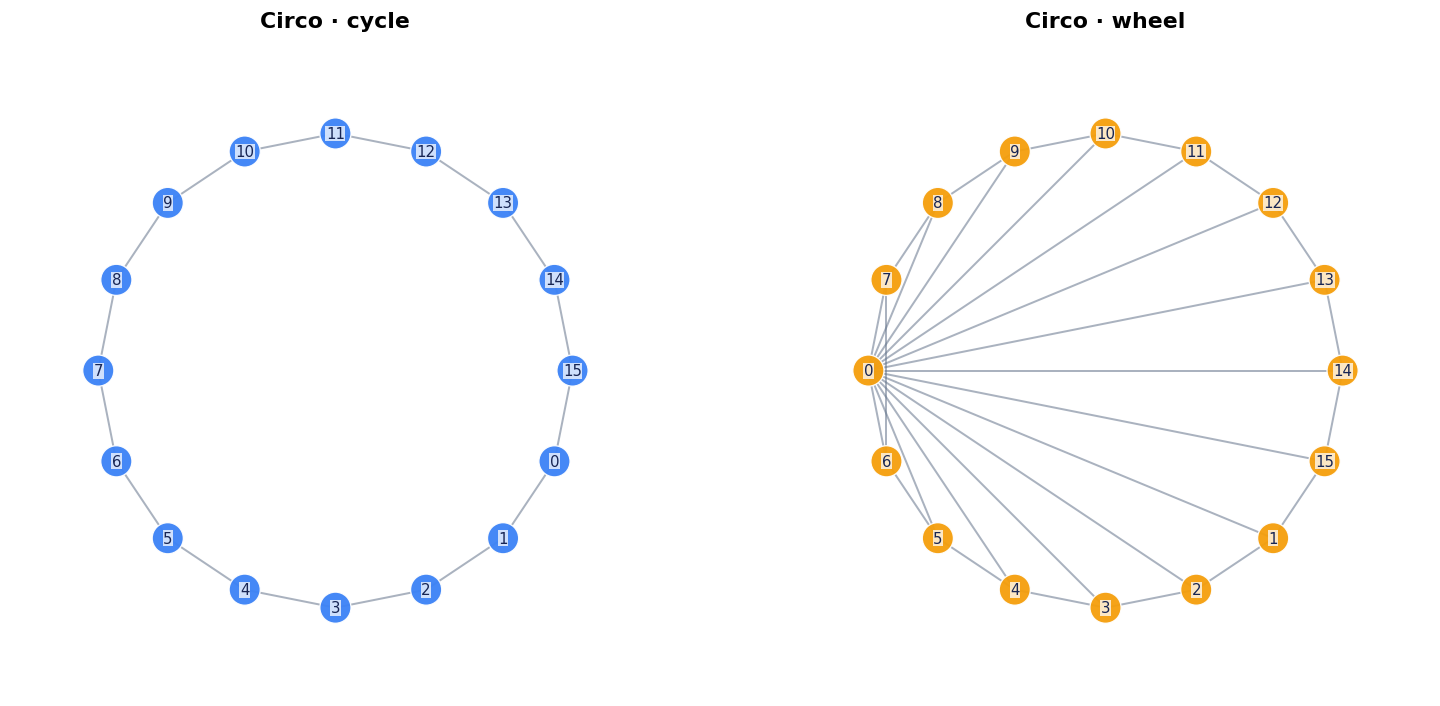

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for G, title, ax in zip([nx.cycle_graph(16), nx.wheel_graph(16)],
                        ['Circo · cycle', 'Circo · wheel'], axes):
    colors = [PALETTE[1] if G.degree(n) > 2 else PALETTE[0] for n in G]
    draw_graph(G, layout(G, 'circo'), title, ax=ax, colors=colors, node_size=350)
fig.tight_layout()
plt.show()

## 5. Twopi: choosing the center of a radial layout
Twopi arranges nodes in layers around a chosen starting node, called the root. A node's layer depends on how many edges you need to follow to reach it from the root along the shortest path.

Both plots below show the same tree, but they use different roots: node `0` on the left and node `10` on the right. An orange outline marks the root in each plot. The node colors show distance from that root, using the same color scale in both panels.

Notice how choosing a different root changes the arrangement and the colors. All the original connections are still present; you are viewing the tree from a different starting point.

**Try it:** Change `roots` from `[0, 10]` to `[0, 39]` and rerun the cell. Node `39` is at the end of a branch. What happens to the layers when you start there? You can also change `r` (the number of children per parent) or `h` (the tree's height) to explore a different tree.

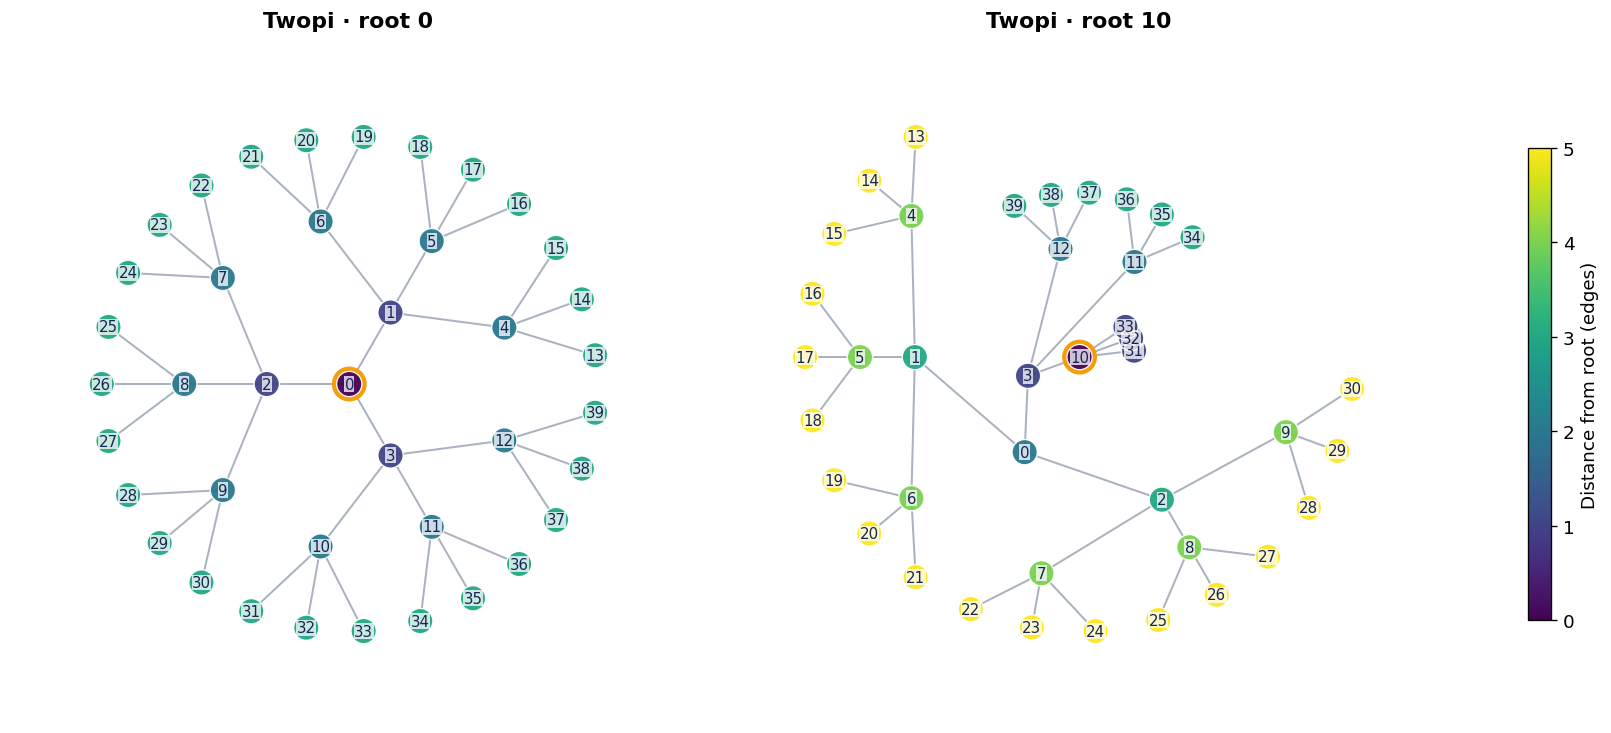

In [14]:
G_tree = nx.balanced_tree(r=3, h=3)
roots = [0, 10]
max_distance = max(max(nx.single_source_shortest_path_length(G_tree, r).values()) for r in roots)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for root, ax in zip(roots, axes):
    distances = nx.single_source_shortest_path_length(G_tree, root)
    colors = [plt.cm.viridis(distances[n] / max_distance) for n in G_tree]
    pos = layout(G_tree, 'twopi', root=root)
    draw_graph(G_tree, pos, f'Twopi · root {root}', ax, colors, node_size=230)
    nx.draw_networkx_nodes(G_tree, pos, nodelist=[root], ax=ax, node_size=340,
                           node_color='none', edgecolors=PALETTE[1], linewidths=2.5)
colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, max_distance), cmap='viridis'),
                       ax=axes, shrink=0.7, ticks=range(max_distance + 1))
colorbar.set_label('Distance from root (edges)')
plt.show()

## 6. Dot: following a workflow
Dot arranges directed graphs in layers, making it useful for workflows and dependencies. In this example, arrows lead from `Start` through several branches that eventually come together at `End`.

The two plots show the same workflow in different orientations. On the left, `rankdir='TB'` makes the main flow run from top to bottom. On the right, `rankdir='LR'` makes it run from left to right. Follow the arrows in each plot and consider which orientation makes the branching and merging easier to read.

**Try it:** Add `G_workflow.add_edge('End', 'Start')` after creating the graph and before computing the layouts. This adds a feedback loop. Dot can still draw the graph, but one or more arrows must now lead back against the main direction of the workflow. Can you spot them?

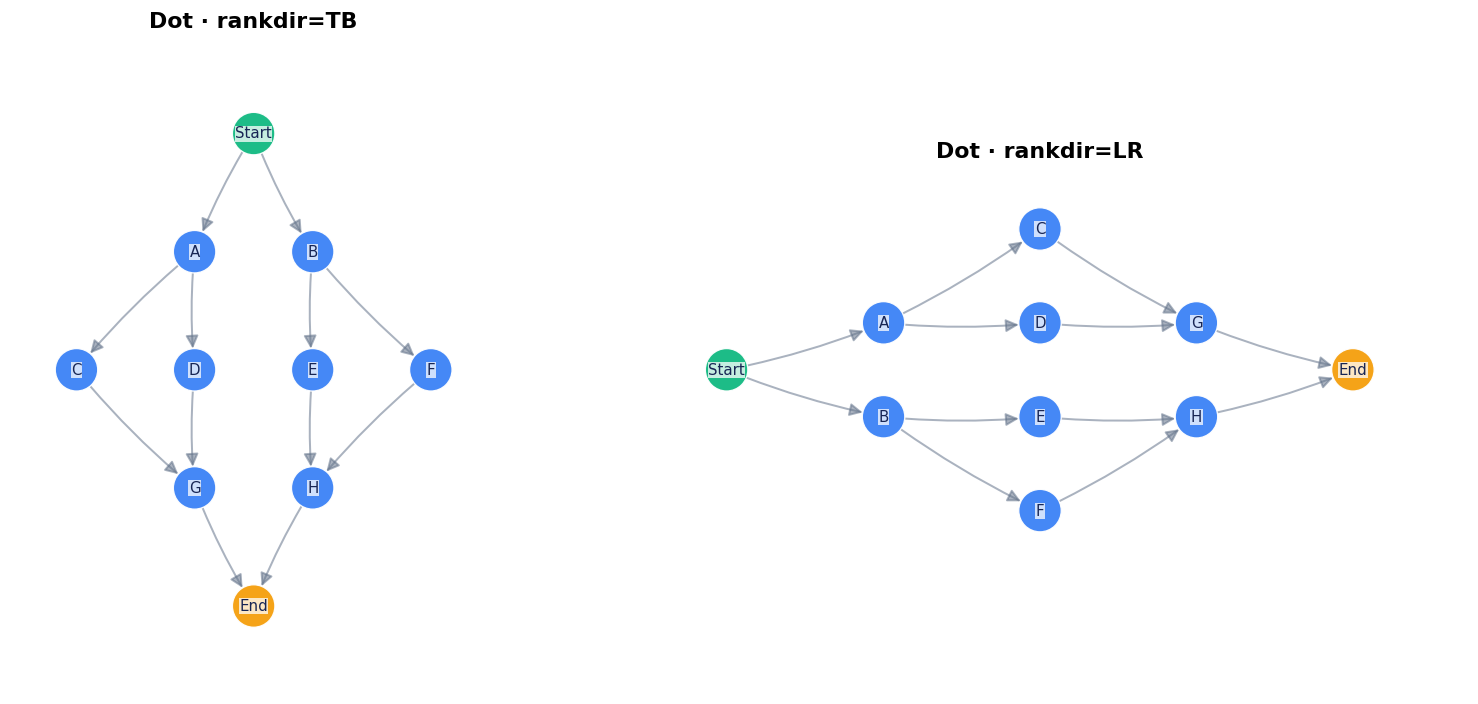

In [15]:
G_workflow = nx.DiGraph([
    ('Start', 'A'), ('Start', 'B'), ('A', 'C'), ('A', 'D'),
    ('B', 'E'), ('B', 'F'), ('C', 'G'), ('D', 'G'),
    ('E', 'H'), ('F', 'H'), ('G', 'End'), ('H', 'End')])
workflow_colors = [PALETTE[2] if n == 'Start' else PALETTE[1] if n == 'End' else PALETTE[0]
                   for n in G_workflow]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for rankdir, ax in zip(['TB', 'LR'], axes):
    draw_graph(G_workflow, layout(G_workflow, 'dot', rankdir=rankdir),
               f'Dot · rankdir={rankdir}', ax, workflow_colors, node_size=650)
fig.tight_layout()
plt.show()

## 7. Patchwork: showing grouped quantities as a treemap
Patchwork produces a treemap: a drawing made of rectangles whose areas represent quantities. This is useful when you want to compare the sizes of items and see how they belong to larger groups.

Here, each item has a weight set by its `area` value. For example, A1 has a weight of `6`, while A2 has a weight of `3`, so A1 should occupy roughly twice as much space. The labels show these weights, and the colors identify the three groups. Items in the same group are placed together.

This example calls Graphviz directly because we need the rectangles it draws, rather than positions for circular nodes. The resulting image appears below the cell and is also saved as `patchwork_demo.png` in the Colab runtime.

**Try it:** Change A1's `area=6` to `area=12` and update its label to `A1 (12)`. Rerun the cell and compare its size with the other rectangles. How does increasing one item's weight change the space available to the others?

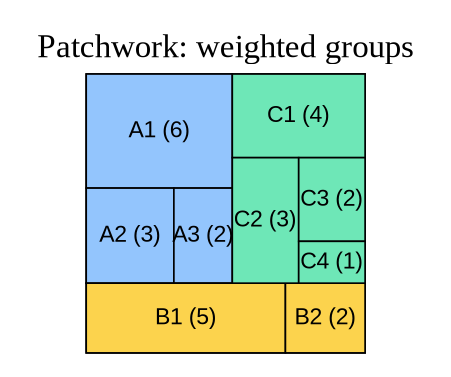

Saved: patchwork_demo.png


In [16]:
DOT_PATCHWORK = r'''
graph G {
  graph [label="Patchwork: weighted groups", labelloc=t, fontsize=20, pad=0.2];
  node [style=filled, fontname="Helvetica", fontsize=14];
  subgraph cluster_a {
    label="Group A";
    a1 [label="A1 (6)", area=6, fillcolor="#93C5FD"];
    a2 [label="A2 (3)", area=3, fillcolor="#93C5FD"];
    a3 [label="A3 (2)", area=2, fillcolor="#93C5FD"];
  }
  subgraph cluster_b {
    label="Group B";
    b1 [label="B1 (5)", area=5, fillcolor="#FCD34D"];
    b2 [label="B2 (2)", area=2, fillcolor="#FCD34D"];
  }
  subgraph cluster_c {
    label="Group C";
    c1 [label="C1 (4)", area=4, fillcolor="#6EE7B7"];
    c2 [label="C2 (3)", area=3, fillcolor="#6EE7B7"];
    c3 [label="C3 (2)", area=2, fillcolor="#6EE7B7"];
    c4 [label="C4 (1)", area=1, fillcolor="#6EE7B7"];
  }
}
'''


def render_patchwork(dot_text, out_path='patchwork_demo.png'):
    result = subprocess.run(['patchwork', '-Tpng', '-Gdpi=120'],
                            input=dot_text.encode('utf-8'), capture_output=True)
    if result.returncode:
        raise RuntimeError(result.stderr.decode('utf-8', errors='replace'))
    with open(out_path, 'wb') as f:
        f.write(result.stdout)
    display(Image(data=result.stdout))
    print(f'Saved: {out_path}')

render_patchwork(DOT_PATCHWORK)

## A few more things to explore
Once you have run the examples, try using different layout engines on the same graph. This is a useful way to see what each layout brings into focus.

- Add SFDP to the Neato and FDP comparison using `G_small`. Which arrangement makes the three groups easiest to see?
- Draw the same tree with Dot and Twopi. Which makes parent–child relationships easier to follow? Which makes distances from the root easier to see?
- Add another branch or feedback edge to the workflow, then compare the top-to-bottom and left-to-right drawings again.
- Give the Patchwork weights a concrete meaning, such as hours spent on tasks or storage used by folders. Update the labels to match. These quantities must be supplied explicitly; Patchwork does not calculate them from the graph's connections.

For more details, see the [Graphviz layout engines](https://graphviz.org/docs/layouts/) and the [NetworkX graphviz_layout reference](https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pydot.graphviz_layout.html).